# 04.2 SVM (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con el experimento 1 y con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma que en el experimento 1.
- Hiperparámetros: salen de la búsqueda con Optuna del experimento 2 (carpeta `04-hyperparameter-optimization-experiment-2`), con `load_best(...)`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- No usar `test`.

## Hipótesis del experimento 2

El experimento 1 dejó al SVM en macro-F1 0,501 (clasificación) y R² 0,214 (regresión). En este experimento comprobamos si tres cambios lo mejoran. Cada uno es una hipótesis que el resultado confirmará o no.

| Cambio | Hipótesis |
|---|---|
| 1. Agregar raza, color y ciudad (`breed_main`, `color_main`, `city`) | Con más información sobre cada animal, el SVM distingue mejor entre casos parecidos, sobre todo al predecir los días hasta la adopción |
| 2. Edad en logaritmo (`age_log`), solo en regresión | Con la edad en logaritmo, el SVM compara mejor a los animales y mejora la regresión |
| 3. Ampliar el rango de `epsilon` de 0,01–0,5 a 0,05–1 (regresión) | Con un rango más amplio, Optuna puede encontrar un valor mejor |

**Lo que no cambia.** Se mantienen las variables de fecha y hora, que describen la época del año y la tendencia de los ingresos. También son iguales la validación, la semilla y el número de pruebas.

In [4]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, SVR

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import load_best

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

## Inputs

Variables del experimento 2 para SVM. Frente al experimento 1 se agregan raza, color y ciudad (`CAT_HIGH`) y, en regresión, la edad se usa en logaritmo (`age_log`) en lugar de `age_days`.

In [5]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'prior_stays', 'hour', 'month', 't_months', 'age_log']


## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 2. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [6]:
folder = "../04-hyperparameter-optimization-experiment-2"
params_clf = load_best("svm_clf", FEATURES_EXP2_CLF, folder=folder)
params_reg = load_best("svm_reg", FEATURES_EXP2_REG, folder=folder)

Ajustes cargados de svm_clf.json: {'C': 85.5899799306277, 'gamma': 0.011820522191423363, 'class_weight': None}
(en la búsqueda: macro-F1 = 0.5047)
Ajustes cargados de svm_reg.json: {'C': 1.1175675512644023, 'gamma': 0.16982551822621966, 'epsilon': 0.18323695180334754}
(en la búsqueda: R² (en log) = 0.3444)


## 1. Clasificación

Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio. Tarda entre 25 y 45 minutos, más que en el experimento 1 porque hay más columnas.

macro-F1: 0.513  (siempre la clase más frecuente: 0.119)

                 precision    recall  f1-score   support

       Adoption       0.59      0.82      0.69     27073
     Euthanasia       0.76      0.65      0.70      4986
          Other       0.77      0.03      0.06       834
Return to Owner       0.64      0.64      0.64     11757
       Transfer       0.68      0.37      0.48     19031

       accuracy                           0.63     63681
      macro avg       0.69      0.50      0.51     63681
   weighted avg       0.64      0.63      0.61     63681



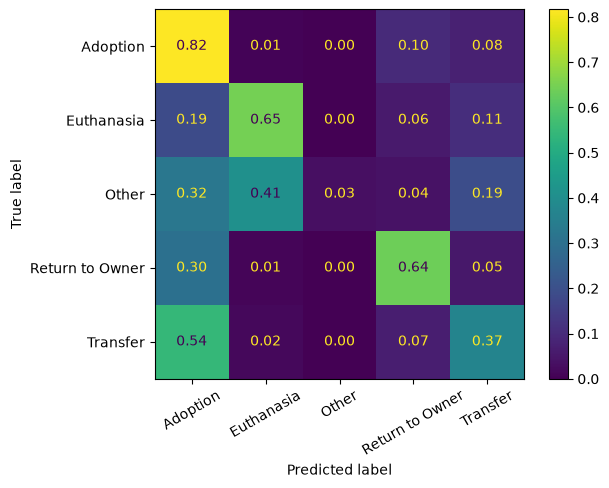

In [7]:
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)), ("model", SVC(**params_clf))])
X_clf = data[FEATURES_EXP2_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

El error se reporta en días (`np.expm1`) y el R² en log.

In [8]:
pipe_reg = Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)),
                     ("model", SVR(**params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP2_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
base_log = cross_val_predict(DummyRegressor(strategy="median"), X_reg, y_reg, groups=groups_reg, cv=cv)

days_real = np.expm1(y_reg)
pd.DataFrame({
    "R² (log)": [r2_score(y_reg, pred_log), r2_score(y_reg, base_log)],
    "MAE (días)": [mean_absolute_error(days_real, np.expm1(pred_log)), mean_absolute_error(days_real, np.expm1(base_log))],
}, index=["SVR", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
SVR,0.345,19.626
Siempre la mediana,-0.058,24.312


## 3. Resultados frente al experimento 1

In [9]:
exp1 = {"Clasificación (macro-F1)": 0.501, "Regresión (R² log)": 0.214, "Regresión (MAE días)": 21.373}  # SVM, experimento 1
exp2 = {"Clasificación (macro-F1)": f1_score(y_clf, pred_clf, average="macro"),
        "Regresión (R² log)": r2_score(y_reg, pred_log),
        "Regresión (MAE días)": mean_absolute_error(days_real, np.expm1(pred_log))}

pd.DataFrame({"Experimento 1": exp1, "Experimento 2": exp2}).T.round(3)

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
Experimento 1,0.501,0.214,21.373
Experimento 2,0.513,0.345,19.626


## 4. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Estos son los resultados de cada uno, con los mismos folds en todos los modelos, así que se pueden comparar fold por fold. No vuelve a entrenar nada: usa las predicciones de arriba.

In [10]:
rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

rows_reg = []
for fold, (_, val) in enumerate(cv.split(X_reg, y_reg, groups_reg), start=1):
    rows_reg.append({"fold": fold, "filas": len(val),
                     "R² (log)": r2_score(y_reg.iloc[val], pred_log[val]),
                     "MAE (días)": mean_absolute_error(days_real.iloc[val], np.expm1(pred_log[val]))})

for title, rows in [("Clasificación", rows_clf), ("Regresión", rows_reg)]:
    table = pd.DataFrame(rows).set_index("fold")
    summary = table.drop(columns="filas").agg(["mean", "std"])
    print(f"=== {title}: resultado por fold ===")
    print(table.round(3).to_string())
    print(summary.round(3).to_string(), "\n")

=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud
fold                            
1     12729     0.502      0.621
2     12783     0.512      0.626
3     12697     0.514      0.624
4     12733     0.516      0.628
5     12739     0.520      0.634
      macro-F1  exactitud
mean     0.513      0.627
std      0.007      0.005 

=== Regresión: resultado por fold ===
      filas  R² (log)  MAE (días)
fold                             
1      5393     0.337      20.026
2      5453     0.310      19.898
3      5401     0.372      19.650
4      5405     0.340      19.501
5      5421     0.362      19.054
      R² (log)  MAE (días)
mean     0.344      19.626
std      0.024       0.380 

